# **Inspeção dos dados brutos — H&M**

### **Objetivo**

1. Trabalhar com 1 foco central: Cliente.  Para isso analisar o comportamento de compra dos clientes da H&M para identificar segmentos, grupos de produtos e padrões de canal associados à recorrência para apoiar a priorização de ações de CRM e decisões de produtos.

```Nota: Editado conforme avançado o projeto```

In [ ]:
## importação de sistema
import os
from pathlib import Path

## importação de análise
import pandas as pd
import numpy as np
from dotenv import load_dotenv
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

## configurações visuais
pd.options.display.max_columns = None
pd.options.display.float_format = "{:.3f}".format

In [ ]:
## definição do diretório e arquivos brutos
load_dotenv()

DATA_DIR = Path(os.environ["HM_RAW_DIR"])

ARTICLES_FILE = DATA_DIR / "articles.csv"
CUSTOMERS_FILE = DATA_DIR / "customers.csv"
TRANSACTIONS_FILE = DATA_DIR / "transactions_train.csv"

In [3]:
## Carregamento das bases
articles = pd.read_csv(ARTICLES_FILE)
customers = pd.read_csv(CUSTOMERS_FILE)
transactions = pd.read_csv(TRANSACTIONS_FILE)

In [4]:
## visualização da base articles
articles.head()

,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,4,Dark,5,Black,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,3,Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,1,Dusty Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,4,Dark,5,Black,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,3,Light,9,White,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


In [5]:
## visualização da base customers
customers.head()

,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.000,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.000,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.000,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.000,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.000,1.000,ACTIVE,Regularly,52.000,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...


In [6]:
## visualização da base transactions
transactions.head()

,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.051,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.017,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.017,2


In [7]:
## verificação inicial do tamanho das bases
bases = ({
    "articles" : articles,
    "customers" : customers,
    "transactions" : transactions
})

for nome,base in bases.items():
    df = pd.DataFrame(base)
    print ("shape base {}: {}".format(nome, df.shape))


shape base articles: (105542, 25)
shape base customers: (1371980, 7)
shape base transactions: (31788324, 5)


# **Inspeção - Articles**

In [8]:
## Articles - Inspeção

print (f"shape base:", articles.shape)
display(articles.head())
articles.info()
display(articles.describe())


## Pipeline de Inspeção
## 1. A base tem um total de 105542 linhas
## 2. Verificar article id como principal candidata a chave primária e futura chave de ligação com transactions
## 4. Verificar cardinalidade, duplicatas e nulos das colunas
## 5. Verifica os valores únicos e sanity check das colunas com nulos ou valores duplicados

shape base: (105542, 25)


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
0,108775015,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,9,Black,4,Dark,5,Black,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
1,108775044,108775,Strap top,253,Vest top,Garment Upper body,1010016,Solid,10,White,3,Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
2,108775051,108775,Strap top (1),253,Vest top,Garment Upper body,1010017,Stripe,11,Off White,1,Dusty Light,9,White,1676,Jersey Basic,A,Ladieswear,1,Ladieswear,16,Womens Everyday Basics,1002,Jersey Basic,Jersey top with narrow shoulder straps.
3,110065001,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,9,Black,4,Dark,5,Black,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."
4,110065002,110065,OP T-shirt (Idro),306,Bra,Underwear,1010016,Solid,10,White,3,Light,9,White,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre T-shirt bra with underwired, moulde..."


<class 'pandas.DataFrame'>
RangeIndex: 105542 entries, 0 to 105541
Data columns (total 25 columns):
 #   Column                        Non-Null Count   Dtype
---  ------                        --------------   -----
 0   article_id                    105542 non-null  int64
 1   product_code                  105542 non-null  int64
 2   prod_name                     105542 non-null  str  
 3   product_type_no               105542 non-null  int64
 4   product_type_name             105542 non-null  str  
 5   product_group_name            105542 non-null  str  
 6   graphical_appearance_no       105542 non-null  int64
 7   graphical_appearance_name     105542 non-null  str  
 8   colour_group_code             105542 non-null  int64
 9   colour_group_name             105542 non-null  str  
 10  perceived_colour_value_id     105542 non-null  int64
 11  perceived_colour_value_name   105542 non-null  str  
 12  perceived_colour_master_id    105542 non-null  int64
 13  perceived_colour_master_n

,article_id,product_code,product_type_no,graphical_appearance_no,colour_group_code,perceived_colour_value_id,perceived_colour_master_id,department_no,index_group_no,section_no,garment_group_no
count,105542.000,105542.000,105542.000,105542.000,105542.000,105542.000,105542.000,105542.000,105542.000,105542.000,105542.000
mean,698424569.097,698424.563,234.862,1009515.076,32.234,3.206,7.808,4532.778,3.172,42.664,1010.438
std,128462381.336,128462.384,75.049,22413.586,28.086,1.564,5.377,2712.692,4.353,23.260,6.731
min,108775015.000,108775.000,-1.000,-1.000,-1.000,-1.000,-1.000,1201.000,1.000,2.000,1001.000
25%,616992501.000,616992.500,252.000,1010008.000,9.000,2.000,4.000,1676.000,1.000,20.000,1005.000
50%,702213001.500,702213.000,259.000,1010016.000,14.000,4.000,5.000,4222.000,2.000,46.000,1009.000
75%,796703001.750,796703.000,272.000,1010016.000,52.000,4.000,11.000,7389.000,4.000,61.000,1017.000
max,959461001.000,959461.000,762.000,1010029.000,93.000,7.000,20.000,9989.000,26.000,97.000,1025.000


In [9]:
## validação da chave article_id
sem_correspondencia = ~transactions["article_id"].isin(articles["article_id"])
sem_correspondencia.sum()

np.int64(0)

In [10]:
## Verificação dos valores únicos para sanity check

colunas_object = articles.select_dtypes(include=['object']).columns.tolist()
print(f"valores únicos das colunas de texto:\n",articles[colunas_object].nunique())



colunas_numericas = articles.select_dtypes(include=["int64"]).columns.to_list()
print(f"\nvalores únicos das colunas numericas:\n",articles[colunas_numericas].nunique())


valores únicos das colunas de texto:
 prod_name                       45875
product_type_name                 131
product_group_name                 19
graphical_appearance_name          30
colour_group_name                  50
perceived_colour_value_name         8
perceived_colour_master_name       20
department_name                   250
index_code                         10
index_name                         10
index_group_name                    5
section_name                       56
garment_group_name                 21
detail_desc                     43404
dtype: int64

valores únicos das colunas numericas:
 article_id                    105542
product_code                   47224
product_type_no                  132
graphical_appearance_no           30
colour_group_code                 50
perceived_colour_value_id          8
perceived_colour_master_id        20
department_no                    299
index_group_no                     5
section_no                        57
garment

C:\Users\Luann\AppData\Local\Temp\ipykernel_10468\1908000844.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_object = articles.select_dtypes(include=['object']).columns.tolist()


In [11]:
## verificar duplicatas
print(f"linhas duplicadas:", articles.duplicated().sum())
print("\n")

## verificar nulos
valores_nulos_articles = [ 'NaN', 'nan', 'None', 'none', 'NA', 'n/a', 'N/A', '', ' ']
article_nulos = articles.replace(valores_nulos_articles, np.nan)
print(articles.isnull().sum())


linhas duplicadas: 0


article_id                        0
product_code                      0
prod_name                         0
product_type_no                   0
product_type_name                 0
product_group_name                0
graphical_appearance_no           0
graphical_appearance_name         0
colour_group_code                 0
colour_group_name                 0
perceived_colour_value_id         0
perceived_colour_value_name       0
perceived_colour_master_id        0
perceived_colour_master_name      0
department_no                     0
department_name                   0
index_code                        0
index_name                        0
index_group_no                    0
index_group_name                  0
section_no                        0
section_name                      0
garment_group_no                  0
garment_group_name                0
detail_desc                     416
dtype: int64


### Análises Iniciais Articles

 1. article_id possui todas linhas de valor único,  possívelmente uma chave para ligar a tabela de transactions, porém terá que se ligar de forma indireta a tabela de customers
 2. product_code começa com os 6 primeiros difitos do article_id - validar, pois pode trazer alguma agrupamento interessante
 3. detail_desc pode ser tirada da análise
 4. Não há linhas duplicadas
 5. Não tem colunas com valores de agregação, apenas numericos descritivos, então o describe não agrega muito, mas revelou valores -1 que precisam ser verificados
 6. n° de nomes únicos de departamentos não bate com o número único de códigos desses departamentos, verificar se é alguma inrregularidade
 7. section n° e section name possuem a mesma incongruencia entre nome e código, verificar se é alguma inrregularidade
 8. colunas que precisam de modificação: 
    article_id e product_code: string
    demais códigos de categorias: category
    nomes e descrições: string;
 9. nomes das colunas ja padronizado, sem espaços caracteres especiais ou letras maiusculas

    


In [ ]:
##verificação das linhas com -1 registradas no describe

negative_codes = articles[colunas_numericas].eq(-1).sum()
negative_codes = negative_codes[negative_codes > 0]

for column in negative_codes.index:
    print(f"\nRegistros com -1 em {column}:")
    display(articles.loc[articles[column] == -1].head())


Registros com -1 em product_type_no:


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
64,156224002,156224,Box 4p Socks,-1,Unknown,Unknown,1010016,Solid,9,Black,4,Dark,5,Black,3608,Tights basic,B,Lingeries/Tights,1,Ladieswear,62,"Womens Nightwear, Socks & Tigh",1021,Socks and Tights,Semi-matte socks with a short shaft. 20 denier.
4015,473954008,473954,OP Cheeky hipster 2p,-1,Unknown,Unknown,1010016,Solid,9,Black,4,Dark,5,Black,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre hipster briefs with a low waist, li..."
4016,473954013,473954,OP Cheeky hipster 2p,-1,Unknown,Unknown,1010016,Solid,12,Light Beige,1,Dusty Light,11,Beige,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre hipster briefs with a low waist, li..."
4017,473954014,473954,OP Cheeky hipster 2p,-1,Unknown,Unknown,1010016,Solid,17,Yellowish Brown,2,Medium Dusty,13,Brown,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre hipster briefs with a low waist, li..."
4018,473954015,473954,OP Cheeky hipster 2p,-1,Unknown,Unknown,1010016,Solid,17,Yellowish Brown,4,Dark,13,Brown,1339,Clean Lingerie,B,Lingeries/Tights,1,Ladieswear,61,Womens Lingerie,1017,"Under-, Nightwear","Microfibre hipster briefs with a low waist, li..."



Registros com -1 em graphical_appearance_no:


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
1099,317055012,317055,Racer Tank Fancy License,253,Vest top,Garment Upper body,-1,Unknown,9,Black,4,Dark,5,Black,5962,Jersey Fancy DS,D,Divided,2,Divided,58,Divided Selected,1005,Jersey Fancy,"Vest top in cotton jersey with worn details, a..."
1171,323274002,323274,SIGGE LICENSE (1),302,Socks,Socks & Tights,-1,Unknown,9,Black,4,Dark,5,Black,3937,UW,D,Divided,2,Divided,51,Divided Basics,1017,"Under-, Nightwear",Fine-knit trainer socks in various colours and...
4809,487054013,487054,TP Harry 5-p lic anklesock SB,302,Socks,Socks & Tights,-1,Unknown,9,Black,4,Dark,5,Black,4214,Kids Boy Socks,H,Children Sizes 92-140,4,Baby/Children,72,Boys Underwear & Basics,1021,Socks and Tights,"Socks in a soft, jacquard-knit cotton blend."
5441,495742001,495742,CSP TD Flame shirt,259,Shirt,Garment Upper body,-1,Unknown,9,Black,4,Dark,5,Black,5731,Shirt,F,Menswear,3,Menswear,23,Men Suits & Tailoring,1011,Shirts,Shirt in a patterned cotton weave with a turn-...
11483,547937015,547937,Canterbury,252,Sweater,Garment Upper body,-1,Unknown,7,Grey,2,Medium Dusty,12,Grey,1610,Knitwear,A,Ladieswear,1,Ladieswear,6,Womens Casual,1003,Knitwear,"Jumper in a soft, fine knit containing some wo..."



Registros com -1 em colour_group_code:


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
21238,592986010,592986,Cool tiebelt dressed,272,Trousers,Garment Lower body,-1,Unknown,-1,Unknown,-1,Unknown,-1,Unknown,1717,Trouser,A,Ladieswear,1,Ladieswear,11,Womens Tailoring,1009,Trousers,"Wide, high-waisted trousers in woven fabric wi..."
39690,662344003,662344,Lily blouse,258,Blouse,Garment Upper body,-1,Unknown,-1,Unknown,-1,Unknown,-1,Unknown,1515,Blouse,A,Ladieswear,1,Ladieswear,11,Womens Tailoring,1010,Blouses,Long-sleeved blouse in satin with a small stan...
40806,665665001,665665,J LORENZO TRS EQ,272,Trousers,Garment Lower body,-1,Unknown,-1,Unknown,-1,Unknown,-1,Unknown,3030,Equatorial Assortment,A,Ladieswear,1,Ladieswear,15,Womens Everyday Collection,1001,Unknown,Leggings in soft jersey made from a viscose bl...
49595,694968001,694968,Sagus Jogger,272,Trousers,Garment Lower body,-1,Unknown,-1,Unknown,-1,Unknown,-1,Unknown,5882,Jersey Fancy,F,Menswear,3,Menswear,55,Contemporary Street,1005,Jersey Fancy,Joggers in sweatshirt fabric with an elasticat...
49597,694968004,694968,Sagus Jogger,272,Trousers,Garment Lower body,-1,Unknown,-1,Unknown,-1,Unknown,-1,Unknown,5882,Jersey Fancy,F,Menswear,3,Menswear,55,Contemporary Street,1005,Jersey Fancy,Joggers in sweatshirt fabric with an elasticat...



Registros com -1 em perceived_colour_value_id:


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
21238,592986010,592986,Cool tiebelt dressed,272,Trousers,Garment Lower body,-1,Unknown,-1,Unknown,-1,Unknown,-1,Unknown,1717,Trouser,A,Ladieswear,1,Ladieswear,11,Womens Tailoring,1009,Trousers,"Wide, high-waisted trousers in woven fabric wi..."
39690,662344003,662344,Lily blouse,258,Blouse,Garment Upper body,-1,Unknown,-1,Unknown,-1,Unknown,-1,Unknown,1515,Blouse,A,Ladieswear,1,Ladieswear,11,Womens Tailoring,1010,Blouses,Long-sleeved blouse in satin with a small stan...
40806,665665001,665665,J LORENZO TRS EQ,272,Trousers,Garment Lower body,-1,Unknown,-1,Unknown,-1,Unknown,-1,Unknown,3030,Equatorial Assortment,A,Ladieswear,1,Ladieswear,15,Womens Everyday Collection,1001,Unknown,Leggings in soft jersey made from a viscose bl...
49595,694968001,694968,Sagus Jogger,272,Trousers,Garment Lower body,-1,Unknown,-1,Unknown,-1,Unknown,-1,Unknown,5882,Jersey Fancy,F,Menswear,3,Menswear,55,Contemporary Street,1005,Jersey Fancy,Joggers in sweatshirt fabric with an elasticat...
49597,694968004,694968,Sagus Jogger,272,Trousers,Garment Lower body,-1,Unknown,-1,Unknown,-1,Unknown,-1,Unknown,5882,Jersey Fancy,F,Menswear,3,Menswear,55,Contemporary Street,1005,Jersey Fancy,Joggers in sweatshirt fabric with an elasticat...



Registros com -1 em perceived_colour_master_id:


,article_id,product_code,prod_name,product_type_no,product_type_name,product_group_name,graphical_appearance_no,graphical_appearance_name,colour_group_code,colour_group_name,perceived_colour_value_id,perceived_colour_value_name,perceived_colour_master_id,perceived_colour_master_name,department_no,department_name,index_code,index_name,index_group_no,index_group_name,section_no,section_name,garment_group_no,garment_group_name,detail_desc
1095,316657008,316657,Karenina Jacket,262,Jacket,Garment Upper body,1010016,Solid,7,Grey,2,Medium Dusty,-1,Unknown,5960,Outdoor/Blazers DS,D,Divided,2,Divided,58,Divided Selected,1007,Outdoor,Biker jacket in imitation leather with a diago...
1352,342034019,342034,Indiana Solid Scarf,80,Scarf,Accessories,1010016,Solid,10,White,3,Light,-1,Unknown,3409,Scarves,C,Ladies Accessories,1,Ladieswear,65,Womens Big accessories,1019,Accessories,"Scarf in a soft, loose weave with fringes on t..."
1665,368300006,368300,Rock Relaxed Shorts,274,Shorts,Garment Lower body,1010016,Solid,6,Light Grey,3,Light,-1,Unknown,5687,Shorts,F,Menswear,3,Menswear,20,Contemporary Smart,1025,Shorts,"Shorts in soft, washed cotton twill with an el..."
1881,380609037,380609,Livia Top,255,T-shirt,Garment Upper body,1010001,All over pattern,7,Grey,2,Medium Dusty,-1,Unknown,5962,Jersey Fancy DS,D,Divided,2,Divided,58,Divided Selected,1005,Jersey Fancy,Short-sleeved top in airy jersey with a rounde...
1969,387426012,387426,Goodman light shorts,274,Shorts,Garment Lower body,1010014,Placement print,8,Dark Grey,4,Dark,-1,Unknown,8394,Men Sport Bottoms,S,Sport,26,Sport,22,Men H&M Sport,1005,Jersey Fancy,"Ultra-light running shorts in fast-drying, fun..."


In [13]:
department_validation = (
    articles.groupby("department_no")["department_name"]
    .nunique()
)

department_validation[department_validation > 1]

Series([], Name: department_name, dtype: int64)

In [14]:
section_validation = (
    articles.groupby("section_no")["section_name"]
    .nunique()
)

section_validation[section_validation > 1]

Series([], Name: section_name, dtype: int64)

In [15]:
## verificação do product code ser os primeiros digitos do article_id
(articles["article_id"] // 1000 == articles["product_code"]).all()

np.True_

### Analises finais - Articles

1. "-1" nas colunas identificadas no describe representam o grupo "Unknown". -1 para o código, Unknown par ao nome.
2. os códigos referentes aos departamentos e seções são únicos, e apesar da divergência na quantidade, cada código de departamento está associado a um único nome de departamento, e cada código de seção está associado a um único nome de seção.
3. de fato o product_code corresponde aos 6 primeiros digitos do article_id


# **Inspeção - Customers**

In [16]:
print (f"shape base:", customers.shape)
display(customers.head())
customers.info()
display(customers.describe())

## Pipeline de Inspeção
## 1. A base tem um total de 1371980 linhas
## 2. Verificar customer id como principal candidata a chave primária e futura chave de ligação com products
## 3. Verificar a distribuição da idade
## 4. Verificar cardinalidade, duplicatas e nulos das colunas
## 5. Verifica os valores únicos e sanity check das colunas com nulos ou valores duplicados
## 6. verificar os valores das colunas FN e Active pra ver se é possível trocar pra string ou categorical, caso seja uma representação booleana
## 7. padronizar os valores das colunas club e fashion pra todas minusculas ou maiusculas
## 8. Definir as colunas que irão ter o tipo trocado


shape base: (1371980, 7)


,customer_id,FN,Active,club_member_status,fashion_news_frequency,age,postal_code
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.000,52043ee2162cf5aa7ee79974281641c6f11a68d276429a...
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.000,2973abc54daa8a5f8ccfe9362140c63247c5eee03f1d93...
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.000,64f17e6a330a85798e4998f62d0930d14db8db1c054af6...
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.000,5d36574f52495e81f019b680c843c443bd343d5ca5b1c2...
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.000,1.000,ACTIVE,Regularly,52.000,25fa5ddee9aac01b35208d01736e57942317d756b32ddd...


<class 'pandas.DataFrame'>
RangeIndex: 1371980 entries, 0 to 1371979
Data columns (total 7 columns):
 #   Column                  Non-Null Count    Dtype  
---  ------                  --------------    -----  
 0   customer_id             1371980 non-null  str    
 1   FN                      476930 non-null   float64
 2   Active                  464404 non-null   float64
 3   club_member_status      1365918 non-null  str    
 4   fashion_news_frequency  1355969 non-null  str    
 5   age                     1356119 non-null  float64
 6   postal_code             1371980 non-null  str    
dtypes: float64(3), str(4)
memory usage: 256.7 MB


,FN,Active,age
count,476930.000,464404.000,1356119.000
mean,1.000,1.000,36.387
std,0.000,0.000,14.314
min,1.000,1.000,16.000
25%,1.000,1.000,24.000
50%,1.000,1.000,32.000
75%,1.000,1.000,49.000
max,1.000,1.000,99.000


In [17]:
## validação da chave customers
sem_correspondencia = ~transactions["customer_id"].isin(customers["customer_id"])
sem_correspondencia.sum()

np.int64(0)

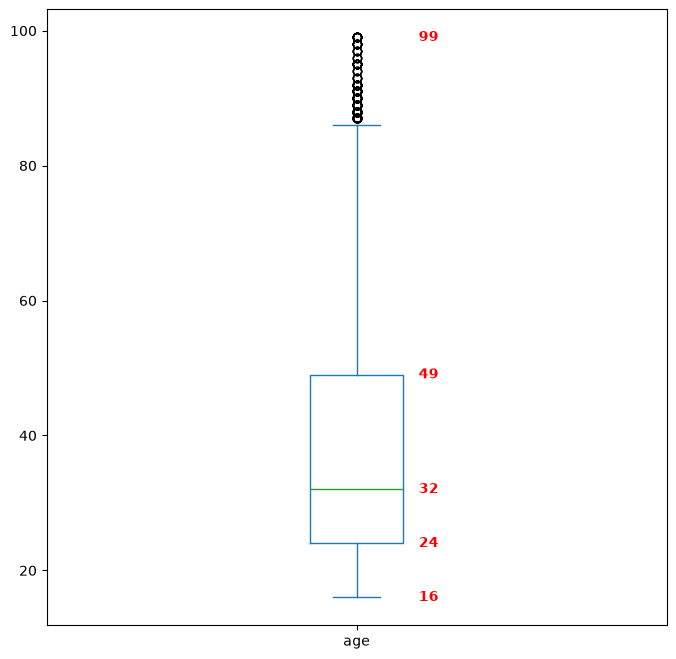

In [ ]:
## análise da variação da idade
ax = customers["age"].plot(kind="box", vert=True, figsize=(8, 8))

valores = customers["age"].quantile([0, 0.25, 0.5, 0.75, 1])

for valor in valores:
    ax.text(1.1, valor, f'{valor:.0f}', va='center', color='red', weight='bold')

plt.show()

In [ ]:
## Duplicatas e valores nulos


print("Linhas duplicadas:", customers.duplicated().sum())

valores_nulos_customers = ["NaN", "nan", "None", "none","NA", "n/a", "N/A", "", " "]

customers_nulos = customers.replace( valores_nulos_customers,np.nan)

## perfil de valores ausentes
perfil_nulos = (
    pd.DataFrame({
        "quantidade": customers_nulos.isna().sum(),
        "percentual": customers_nulos.isna().mean().mul(100).round(2),
    }).sort_values("quantidade", ascending=False)
)

display(perfil_nulos)

Linhas duplicadas: 0


,quantidade,percentual
Active,907576,66.150
FN,895050,65.240
fashion_news_frequency,16011,1.170
age,15861,1.160
club_member_status,6062,0.440
customer_id,0,0.000
postal_code,0,0.000


In [20]:
## Verificação dos valores únicos e sanity check

colunas_object_customers = customers.select_dtypes(include=['object']).columns.tolist()
print(f"valores únicos das colunas de texto:\n",customers[colunas_object_customers].nunique())



colunas_numericas_customers = customers.select_dtypes(include=["float64"]).columns.to_list()
print(f"\nvalores únicos das colunas numericas:\n",customers[colunas_numericas_customers].nunique())

check_unicos_customers = ["FN","Active", "club_member_status", "fashion_news_frequency"]

print("\n")

for column in check_unicos_customers:
    valores_unicos_customers = customers[column].unique()
    print(f"--- Valores únicos em '{column}' ---")
    print(valores_unicos_customers, "\n")

## Analises 

## 1. As colunas FN a Active podem ser trocadas pra string ou categorical, e o nan pode ser substituido por 0
## 2. valores nan em club member pode ser substituido por "NO STATUS"
## 3. valores nan e none em fashion frequency podem ser substituídos pra "NOT FREQUENT"


C:\Users\Luann\AppData\Local\Temp\ipykernel_10468\653420015.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  colunas_object_customers = customers.select_dtypes(include=['object']).columns.tolist()


valores únicos das colunas de texto:
 customer_id               1371980
club_member_status              3
fashion_news_frequency          3
postal_code                352899
dtype: int64

valores únicos das colunas numericas:
 FN         1
Active     1
age       84
dtype: int64


--- Valores únicos em 'FN' ---
[nan  1.] 

--- Valores únicos em 'Active' ---
[nan  1.] 

--- Valores únicos em 'club_member_status' ---
<ArrowStringArray>
['ACTIVE', nan, 'PRE-CREATE', 'LEFT CLUB']
Length: 4, dtype: str 

--- Valores únicos em 'fashion_news_frequency' ---
<ArrowStringArray>
['NONE', 'Regularly', nan, 'Monthly']
Length: 4, dtype: str 



## Análises finais

1. A base possui 1.371.980 clientes

2. `customer_id` não apresenta valores ausentes ou duplicados e possui correspondência para todos os clientes registrados em `transactions`. Portanto, será foi confirmado como chave entre as duas bases.

3. `FN` e `Active` são indicadores registrados como `1` ou ausentes

4. `club_member_status`, `fashion_news_frequency` e `age` possuem baixos percentuais de ausência, que serão preservados sem imputação

5. As idades variam entre 16 e 99 anos, o que traz valores considerados possíveis para o contexto.

6. `postal_code` está anonimizado e não permite análises geográficas, então será deletado na limpeza

7. `FN` e `Active` terão os tipos trocados pra categorical, enquanto `age`irá para inteiro

# Análise Transactions

In [21]:
print (f"shape base:", transactions.shape)
display(transactions.head())
transactions.info()
print(transactions.nunique())
display(transactions.describe())

## Analises iniciais

## 1. A base tem 31788324 registros de itens comprados
## 2. Verificar customer id e article id como possíveis chaves estrangeiras
## 3. verificar a distribuição de "price"
## 4. Checar cardinalidade, duplicatas e nulos
## 5. Verificar o período observado de datas
## 6. Verificar se existem incongruências nas colunas numéricas, como preço nulo ou negativo
## 7. mudar o tipo das colunas: t_dat > data, article_id > string, sales_channel_id > string, sales_id > categorical

shape base: (31788324, 5)


,t_dat,customer_id,article_id,price,sales_channel_id
0,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,663713001,0.051,2
1,2018-09-20,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,541518023,0.030,2
2,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,505221004,0.015,2
3,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687003,0.017,2
4,2018-09-20,00007d2de826758b65a93dd24ce629ed66842531df6699...,685687004,0.017,2


<class 'pandas.DataFrame'>
RangeIndex: 31788324 entries, 0 to 31788323
Data columns (total 5 columns):
 #   Column            Dtype  
---  ------            -----  
 0   t_dat             str    
 1   customer_id       str    
 2   article_id        int64  
 3   price             float64
 4   sales_channel_id  int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 3.4 GB
t_dat                   734
customer_id         1362281
article_id           104547
price                  9857
sales_channel_id          2
dtype: int64


,article_id,price,sales_channel_id
count,31788324.000,31788324.000,31788324.000
mean,696227219.134,0.028,1.704
std,133448003.487,0.019,0.456
min,108775015.000,0.000,1.000
25%,632803008.000,0.016,1.000
50%,714582003.000,0.025,2.000
75%,786524001.000,0.034,2.000
max,956217002.000,0.592,2.000


In [ ]:
## validação da chave article_id
correspondencia_transactions_articles = ~transactions["article_id"].isin(articles["article_id"])
correspondencia_transactions_articles.sum()

np.int64(0)

In [ ]:

## validação da chave customer_id
correspondencia_transactions_customer = ~transactions["customer_id"].isin(customers["customer_id"])
correspondencia_transactions_customer.sum()

np.int64(0)

In [24]:
## verificar as coberturas nas bases dimensão

clientes_sem_transacao = (
    customers["customer_id"].nunique()
    - transactions["customer_id"].nunique()
)

artigos_sem_transacao = (
    articles["article_id"].nunique()
    - transactions["article_id"].nunique()
)

print("Clientes sem transações:", clientes_sem_transacao)
print("Artigos sem transações:", artigos_sem_transacao)

Clientes sem transações: 9699
Artigos sem transações: 995


In [ ]:
## Duplicatas e valores nulos

print("Linhas duplicadas:", transactions.duplicated().sum())

valores_nulos_transactions = ["NaN", "nan", "None", "none","NA", "n/a", "N/A", "", " "]

transactions_nulos = transactions.replace( valores_nulos_transactions,np.nan)

## perfil de valores ausentes
perfil_nulos_transactions = (
    pd.DataFrame({
        "quantidade": transactions_nulos.isna().sum(),
        "percentual": transactions_nulos.isna().mean().mul(100).round(2),
    }).sort_values("quantidade", ascending=False)
)

display(perfil_nulos_transactions)

Linhas duplicadas: 2974905


,quantidade,percentual
t_dat,0,0.000
customer_id,0,0.000
article_id,0,0.000
price,0,0.000
sales_channel_id,0,0.000


In [ ]:
## checagem das linhas duplicadas
duplicate_mask = transactions.duplicated(keep=False)
duplicated_transactions = transactions.loc[duplicate_mask]

display(duplicated_transactions.head())

## Nesse caso, como as linhas representam transações, linhas duplicadas podem representar múltiplas unidades compradas do mesmo artigo, portanto serão mantidas, já que não existe identificador único do pedido

,t_dat,customer_id,article_id,price,sales_channel_id
14,2018-09-20,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,501820043,0.017,2
15,2018-09-20,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,501820043,0.017,2
17,2018-09-20,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,671505001,0.034,2
18,2018-09-20,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,671505001,0.034,2
19,2018-09-20,000aa7f0dc06cd7174389e76c9e132a67860c5f65f9706...,631848002,0.034,2


In [27]:
## Período e preço observado

print("Período:",transactions["t_dat"].min(), "a", transactions["t_dat"].max())
print("Preços iguais ou inferiores a zero:", transactions["price"].le(0).sum())

Período: 2018-09-20 a 2020-09-22
Preços iguais ou inferiores a zero: 0


## Análises finais

1. A base possui 31.788.324  registros de itens comprados

2. `customer_id` e `article_id` não apresentam valores ausentes e estão inclusos nas bases dimensão

3. As demais colunas não possuem valores nulos

4. `price` representa um valor anonimizado da compra e será mantido como medida relativa de valor comercial, sem interpretação monetária

5. `t_dat` deverá ser convertido para data, `article_id` para texto e `sales_channel_id` para categoria.

# Limpeza e Padronização

0. Criar cópia das bases
1. tirar artciles["details_desc"]
2. mudar articles["articl_id" e articles["product_code"] para string
3. mudar as demais colunas da base articles de códigos para categorical, e colunas de name/descrições para string
4. padronizar os valores das colunas club e fashion, da base customers, pra todas maiusculas
5. deletar a coluna customers[postal_code]
6. FN e Active terão os tipos trocados pra categorical, enquanto age irá para inteiro
7. t_dat deverá ser convertido para data, article_id para texto e sales_channel_id para categoria.
8. Validar alterações
9. Salvar as bases em parquet

In [ ]:
## copia das bases para versão a ser limpa

articles_clean = articles.copy()
customers_clean = customers.copy()
transactions_clean = transactions.copy()


In [29]:
## tirar as colunas que não serão usadas
articles_clean = articles_clean.drop(columns=['detail_desc'])
customers_clean = customers_clean.drop(columns=['postal_code'])

In [30]:
string_columns = [
    "article_id",
    "product_code",
    "prod_name",
    "product_type_name",
    "product_group_name",
    "graphical_appearance_name",
    "colour_group_name",
    "perceived_colour_value_name",
    "perceived_colour_master_name",
    "department_name",
    "index_name",
    "index_group_name",
    "section_name",
    "garment_group_name",
]

category_columns = [
    "product_type_no",
    "graphical_appearance_no",
    "colour_group_code",
    "perceived_colour_value_id",
    "perceived_colour_master_id",
    "department_no",
    "index_code",
    "index_group_no",
    "section_no",
    "garment_group_no",
]

articles_clean[string_columns] = articles_clean[string_columns].astype('string')
articles_clean[category_columns] = articles_clean[category_columns].astype('category')

print(articles_clean.dtypes)

article_id                        string
product_code                      string
prod_name                         string
product_type_no                 category
product_type_name                 string
product_group_name                string
graphical_appearance_no         category
graphical_appearance_name         string
colour_group_code               category
colour_group_name                 string
perceived_colour_value_id       category
perceived_colour_value_name       string
perceived_colour_master_id      category
perceived_colour_master_name      string
department_no                   category
department_name                   string
index_code                      category
index_name                        string
index_group_no                  category
index_group_name                  string
section_no                      category
section_name                      string
garment_group_no                category
garment_group_name                string
dtype: object


In [31]:
## padronizar as colunas "club_member_status" e "fashion_news_frequency" para maiusculas

customers_clean = customers_clean.rename(
    columns={
        "FN": "fn",
        "Active": "active"}
)

colunas_padronizadas_customers = ["club_member_status","fashion_news_frequency" ]

for column in colunas_padronizadas_customers:
    customers_clean[column] = customers_clean[column].str.strip().str.upper()

customers_clean.head()

,customer_id,fn,active,club_member_status,fashion_news_frequency,age
0,00000dbacae5abe5e23885899a1fa44253a17956c6d1c3...,NaN,NaN,ACTIVE,NONE,49.000
1,0000423b00ade91418cceaf3b26c6af3dd342b51fd051e...,NaN,NaN,ACTIVE,NONE,25.000
2,000058a12d5b43e67d225668fa1f8d618c13dc232df0ca...,NaN,NaN,ACTIVE,NONE,24.000
3,00005ca1c9ed5f5146b52ac8639a40ca9d57aeff4d1bd2...,NaN,NaN,ACTIVE,NONE,54.000
4,00006413d8573cd20ed7128e53b7b13819fe5cfc2d801f...,1.000,1.000,ACTIVE,REGULARLY,52.000


In [35]:
## FN e Active para categorical e age inteiro

customers_clean["fn"] = customers_clean["fn"].astype("category")
customers_clean["active"] = customers_clean["active"].astype("category")
customers_clean["age"] = customers_clean["age"].astype("Int64")

customers_clean.dtypes

customer_id                    str
fn                        category
active                    category
club_member_status             str
fashion_news_frequency         str
age                          Int64
dtype: object

In [40]:
## t_dat deverá ser convertido para data, article_id para texto e sales_channel_id para categoria.

transactions_clean["t_dat"] = pd.to_datetime(transactions_clean["t_dat"],format="%Y-%m-%d", errors="coerce")
transactions_clean["article_id"] = transactions_clean["article_id"].astype("string")
transactions_clean["sales_channel_id"] = transactions_clean["sales_channel_id"].astype("category")
print(transactions_clean.dtypes)
print(f"falhas_conversao_data =", transactions_clean["t_dat"].isnull().sum())


t_dat               datetime64[us]
customer_id                    str
article_id                  string
price                      float64
sales_channel_id          category
dtype: object
falhas_conversao_data = 0


In [37]:
## Validação do tamanho pós limpeza
bases_brutas = [articles, customers, transactions]
bases_limpas = [articles_clean, customers_clean, transactions_clean]
nomes_tabelas = ["Articles", "Customers", "Transactions"]


for nome, base_bruta, base_limpa in zip(nomes_tabelas, bases_brutas, bases_limpas):
    
    resumo_validacao = pd.DataFrame({
        "antes": {
            "linhas": len(base_bruta),
            "duplicadas": base_bruta.duplicated().sum(),}
            ,
        "depois": {
            "linhas": len(base_limpa),
            "duplicadas": base_limpa.duplicated().sum(),}
    })
    
    print(f"{nome}")
    display(resumo_validacao)
    print("\n")

Articles


,antes,depois
linhas,105542,105542
duplicadas,0,0




Customers


,antes,depois
linhas,1371980,1371980
duplicadas,0,0




Transactions


,antes,depois
linhas,31788324,31788324
duplicadas,2974905,2974905


In [39]:
## validação dos relacionamentos após a limpeza

artigos_sem_correspondencia = (~transactions_clean["article_id"].isin(articles_clean["article_id"])).sum()
clientes_sem_correspondencia = (~transactions_clean["customer_id"].isin(customers_clean["customer_id"])).sum()

print("Artigos sem correspondência:", artigos_sem_correspondencia)
print("Clientes sem correspondência:", clientes_sem_correspondencia)

Artigos sem correspondência: 0
Clientes sem correspondência: 0


In [42]:
## Exportação das bases tratadas

OUTPUT_DIR = Path.cwd().parent / "data"
OUTPUT_DIR.mkdir(exist_ok=True)

articles_clean.to_parquet(OUTPUT_DIR / "articles_clean.parquet",index=False,compression="snappy")

customers_clean.to_parquet(OUTPUT_DIR / "customers_clean.parquet",index=False,compression="snappy")

transactions_clean.to_parquet(OUTPUT_DIR / "transactions_clean.parquet",index=False,compression="snappy")

print("Bases exportadas em:", OUTPUT_DIR.resolve())

Bases exportadas em: E:\Area de Trabalho\Formação em Ciencia de Dados-ComunidadeDS-2023\Revisões\Portifolio\hm\hm-analytics\data


In [45]:
## Verificação dos parquets
parquet_files = [
OUTPUT_DIR / "articles_clean.parquet",
OUTPUT_DIR / "customers_clean.parquet",
OUTPUT_DIR / "transactions_clean.parquet",
]

for file in parquet_files:
    metadata = pq.ParquetFile(file).metadata
    print(f"Arquivo: {file.name}")
    print(f"Linhas: {metadata.num_rows}")
    print(f"Colunas: {metadata.num_columns}")
    print()

Arquivo: articles_clean.parquet
Linhas: 105542
Colunas: 24

Arquivo: customers_clean.parquet
Linhas: 1371980
Colunas: 6

Arquivo: transactions_clean.parquet
Linhas: 31788324
Colunas: 5

